In [8]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://api.openf1.org/v1/sessions"

params = {
    "year": 2024,
    "session_name": "Race"
}

response = requests.get(url, params=params, timeout=30)

response.raise_for_status()

sessions = pd.DataFrame(response.json())

print(sessions[['session_key', 'location', 'session_name']])

    session_key           location session_name
0          9472             Sakhir         Race
1          9480             Jeddah         Race
2          9488          Melbourne         Race
3          9496             Suzuka         Race
4          9673           Shanghai         Race
5          9507              Miami         Race
6          9515              Imola         Race
7          9523             Monaco         Race
8          9531           Montréal         Race
9          9539          Barcelona         Race
10         9550          Spielberg         Race
11         9558        Silverstone         Race
12         9566           Budapest         Race
13         9574  Spa-Francorchamps         Race
14         9582          Zandvoort         Race
15         9590              Monza         Race
16         9598               Baku         Race
17         9606         Marina Bay         Race
18         9617             Austin         Race
19         9625        Mexico City      

In [9]:
abu_dhabi = sessions[
    sessions['location'].str.contains(
        'Abu Dhabi',
        case=False,
        na=False
    )
]

print(abu_dhabi[['session_key', 'location', 'session_name']])

Empty DataFrame
Columns: [session_key, location, session_name]
Index: []


In [10]:
print("Total sessions:", len(sessions))

print("\nAvailable columns:")
print(sessions.columns.tolist())

print("\n2024 race locations:")
print(sessions['location'].unique())

Total sessions: 24

Available columns:
['session_key', 'session_type', 'session_name', 'date_start', 'date_end', 'meeting_key', 'circuit_key', 'circuit_short_name', 'country_key', 'country_code', 'country_name', 'location', 'gmt_offset', 'year', 'is_cancelled']

2024 race locations:
['Sakhir' 'Jeddah' 'Melbourne' 'Suzuka' 'Shanghai' 'Miami' 'Imola'
 'Monaco' 'Montréal' 'Barcelona' 'Spielberg' 'Silverstone' 'Budapest'
 'Spa-Francorchamps' 'Zandvoort' 'Monza' 'Baku' 'Marina Bay' 'Austin'
 'Mexico City' 'São Paulo' 'Las Vegas' 'Lusail' 'Yas Island']


In [11]:
abu_dhabi = sessions[
    sessions['location'] == 'Yas Island'
]

print(
    abu_dhabi[
        ['session_key', 'location', 'country_name', 'session_name']
    ]
)

    session_key    location          country_name session_name
23         9662  Yas Island  United Arab Emirates         Race


In [12]:
session_key = abu_dhabi.iloc[0]['session_key']

print("Abu Dhabi session key:", session_key)

Abu Dhabi session key: 9662


In [13]:
url = "https://api.openf1.org/v1/laps"

params = {
    "session_key": session_key
}

response = requests.get(url, params=params, timeout=30)

response.raise_for_status()

laps = pd.DataFrame(response.json())

print("Total lap records:", len(laps))

laps.head()

Total lap records: 1037


,meeting_key,session_key,driver_number,lap_number,date_start,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,is_pit_out_lap,lap_duration,segments_sector_1,segments_sector_2,segments_sector_3,st_speed
0,1252,9662,55,1,2024-12-08T13:03:35.033000+00:00,22.217,38.437,32.859,285.0,289.0,False,93.513,"[2048, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2051, 204...","[2049, 2049, 2049, 2051, 2051, 2051, 2049, 204...",298.0
1,1252,9662,1,1,2024-12-08T13:03:35.033000+00:00,25.002,39.931,34.944,290.0,302.0,False,99.877,"[2048, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2051, 2049, 2049, 2049, 2049, 204...",289.0
2,1252,9662,4,1,2024-12-08T13:03:35.033000+00:00,20.498,38.405,32.676,281.0,283.0,False,91.579,"[None, 2049, 2051, 2051, 2049]","[2049, 2051, 2049, 2049, 2049, 2051, 2049, 204...","[2049, 2051, 2049, 2049, 2049, 2049, 2049, 204...",293.0
3,1252,9662,81,1,2024-12-08T13:03:35.033000+00:00,30.241,40.179,33.610,285.0,291.0,False,104.030,"[None, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...",295.0
4,1252,9662,10,1,2024-12-08T13:03:35.033000+00:00,22.656,38.658,33.126,287.0,294.0,False,94.440,"[2048, 2049, 2049, 2049, 2051]","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2051, 2049, 2049, 2049, 2049, 2049, 2049, 204...",306.0


In [14]:
print(laps.columns.to_list())

['meeting_key', 'session_key', 'driver_number', 'lap_number', 'date_start', 'duration_sector_1', 'duration_sector_2', 'duration_sector_3', 'i1_speed', 'i2_speed', 'is_pit_out_lap', 'lap_duration', 'segments_sector_1', 'segments_sector_2', 'segments_sector_3', 'st_speed']


In [15]:
print(laps.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1037 entries, 0 to 1036
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   meeting_key        1037 non-null   int64  
 1   session_key        1037 non-null   int64  
 2   driver_number      1037 non-null   int64  
 3   lap_number         1037 non-null   int64  
 4   date_start         1037 non-null   object 
 5   duration_sector_1  1030 non-null   float64
 6   duration_sector_2  1034 non-null   float64
 7   duration_sector_3  1033 non-null   float64
 8   i1_speed           844 non-null    float64
 9   i2_speed           1034 non-null   float64
 10  is_pit_out_lap     1037 non-null   bool   
 11  lap_duration       1033 non-null   float64
 12  segments_sector_1  1035 non-null   object 
 13  segments_sector_2  1035 non-null   object 
 14  segments_sector_3  1034 non-null   object 
 15  st_speed           1034 non-null   float64
dtypes: bool(1), float64(7), 

In [16]:
missingValues = laps.isna().sum()

print(missingValues[missingValues > 0])

duration_sector_1      7
duration_sector_2      3
duration_sector_3      4
i1_speed             193
i2_speed               3
lap_duration           4
segments_sector_1      2
segments_sector_2      2
segments_sector_3      3
st_speed               3
dtype: int64


In [17]:
print("Total Missing Values: ", laps.isna().sum().sum())

# print("Duplicate Rows: ", laps.duplicated().sum())   Gives error


Total Missing Values:  224


In [18]:
duplicate_laps = laps.duplicated(
    subset=['session_key', 'driver_number', 'lap_number']
)

print("Duplicate laps:", duplicate_laps.sum())


Duplicate laps: 0


In [19]:
race_data = laps.copy()

In [20]:
race_data = race_data.dropna(subset=['lap_duration'])

race_data = race_data[race_data['is_pit_out_lap'] == False].copy()

print("Original Records: ", len(laps))
print("Cleaned Records: ", len(race_data))

Original Records:  1037
Cleaned Records:  1005


In [21]:
race_data['lap_duration'].describe()

count    1005.000000
mean       90.507472
std         4.602013
min        85.637000
25%        88.950000
50%        89.735000
75%        90.268000
max       143.554000
Name: lap_duration, dtype: float64

In [22]:
# Slowest Laps

slowest_laps = race_data.sort_values(
    by= 'lap_duration',
    ascending=False
)

print(
    slowest_laps[
        ['driver_number', 'lap_number', 'lap_duration', 'is_pit_out_lap']
    ].head(10)
)

     driver_number  lap_number  lap_duration  is_pit_out_lap
566             77          30       143.554           False
56              43           3       130.710           False
37              43           2       122.028           False
38              81           2       121.916           False
36              22           2       121.592           False
35              61           2       120.814           False
34              23           2       120.191           False
33              24           2       119.827           False
32              77           2       117.544           False
31              44           2       116.731           False


In [23]:
# Fastest Drivers

fastest_drivers = race_data.sort_values(
    by="lap_duration",
    ascending=True
) 

print(
    fastest_drivers[
        ['driver_number', 'lap_number', 'lap_duration', 'is_pit_out_lap']
    ].head(10)
)

      driver_number  lap_number  lap_duration  is_pit_out_lap
1034             20          57        85.637           False
603              20          32        87.235           False
794              44          44        87.278           False
912              44          51        87.319           False
962              44          54        87.342           False
979              44          55        87.398           False
920               4          52        87.438           False
878              44          49        87.490           False
937               4          53        87.520           False
777              44          43        87.556           False


###Driver Performances

In [33]:
driver_performance = race_data.groupby(
    'driver_number'
)["lap_duration"].agg(
    ['mean', 'min', 'max', 'std', 'count']
).round(3)

driver_performance = driver_performance.sort_values(
    by='mean'
)

driver_performance

,mean,min,max,std,count
driver_number,,,,,
4,89.232,87.438,108.349,3.332,57
55,89.335,87.765,109.770,3.439,57
16,89.771,88.018,113.013,3.719,57
44,89.849,87.278,116.731,4.245,57
63,89.868,88.195,109.838,3.430,57
1,89.895,87.765,114.938,3.959,57
81,90.108,87.690,121.916,4.916,56
14,90.261,87.948,110.156,3.485,56
10,90.465,89.212,109.760,3.216,57


In [25]:
url = "https://api.openf1.org/v1/drivers"

params = {
    "session_key": session_key
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

drivers = pd.DataFrame(response.json())

print(
    drivers[
        ['driver_number', 'full_name', 'team_name']
    ].drop_duplicates()
)

    driver_number         full_name        team_name
0               1    Max VERSTAPPEN  Red Bull Racing
1               4      Lando NORRIS          McLaren
2              10      Pierre GASLY           Alpine
3              11      Sergio PEREZ  Red Bull Racing
4              14   Fernando ALONSO     Aston Martin
5              16   Charles LECLERC          Ferrari
6              18      Lance STROLL     Aston Martin
7              20   Kevin MAGNUSSEN     Haas F1 Team
8              22      Yuki TSUNODA               RB
9              23   Alexander ALBON         Williams
10             24       ZHOU Guanyu      Kick Sauber
11             27   Nico HULKENBERG     Haas F1 Team
12             30       Liam LAWSON               RB
13             43  Franco COLAPINTO         Williams
14             44    Lewis HAMILTON         Mercedes
15             55      Carlos SAINZ          Ferrari
16             61       Jack DOOHAN           Alpine
17             63    George RUSSELL         Me

###Merging Drivers with Driver Performances

In [34]:
driver_performance = driver_performance.reset_index()

driver_performance = driver_performance.merge(
    drivers[['driver_number', 'full_name', 'team_name']].drop_duplicates(subset=['driver_number']),
    on="driver_number",
    how='left'
)

driver_performance = driver_performance.sort_values(
    by='mean'
)

print(
    driver_performance[
        ['driver_number', 'full_name', 'team_name', 'mean', 'min', 'max', 'std', 'count']
    ].round(3)
)


    driver_number         full_name        team_name    mean     min      max  \
0               4      Lando NORRIS          McLaren  89.232  87.438  108.349   
1              55      Carlos SAINZ          Ferrari  89.335  87.765  109.770   
2              16   Charles LECLERC          Ferrari  89.771  88.018  113.013   
3              44    Lewis HAMILTON         Mercedes  89.849  87.278  116.731   
4              63    George RUSSELL         Mercedes  89.868  88.195  109.838   
5               1    Max VERSTAPPEN  Red Bull Racing  89.895  87.765  114.938   
6              81     Oscar PIASTRI          McLaren  90.108  87.690  121.916   
7              14   Fernando ALONSO     Aston Martin  90.261  87.948  110.156   
8              10      Pierre GASLY           Alpine  90.465  89.212  109.760   
9              27   Nico HULKENBERG     Haas F1 Team  90.521  89.152  109.887   
10             24       ZHOU Guanyu      Kick Sauber  90.586  87.982  119.827   
11             18      Lance

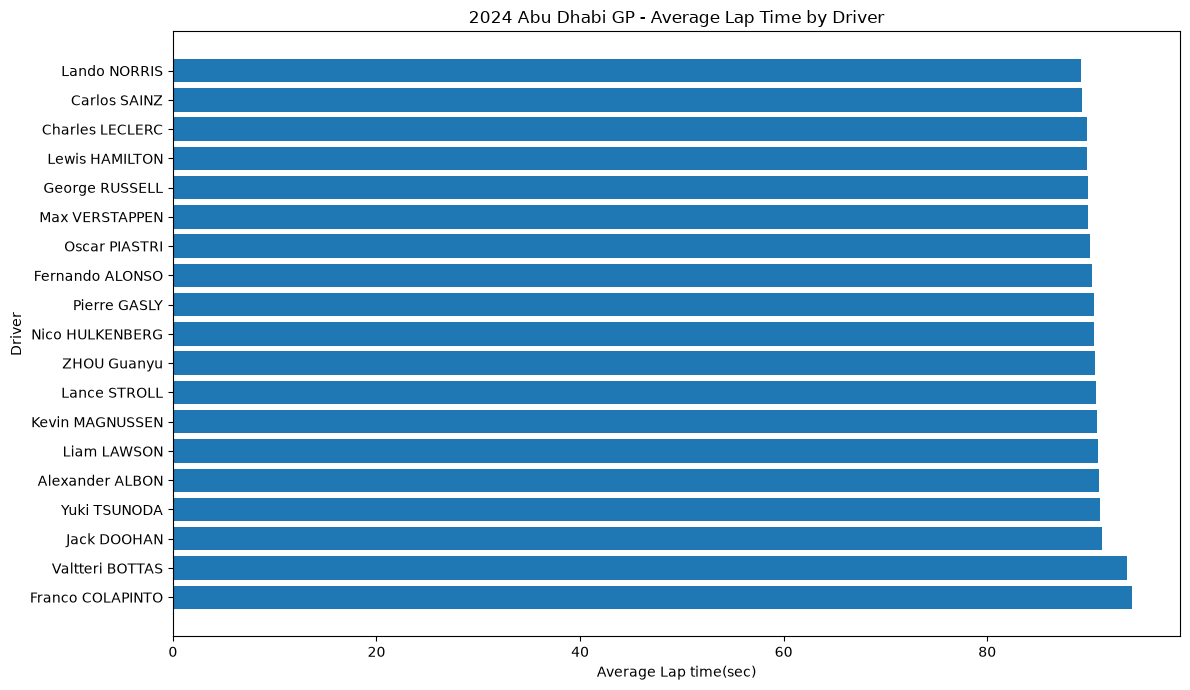

In [27]:
plt.figure(figsize=(12,7))

plt.barh(
    driver_performance['full_name'],
    driver_performance['mean']
)

plt.xlabel("Average Lap time(sec)")
plt.ylabel("Driver")
plt.title("2024 Abu Dhabi GP - Average Lap Time by Driver")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

- **Norris** with the ***lowest Average Lap time*** but not the lowest standard deviation , which shows that **speed is not equal to consistency**

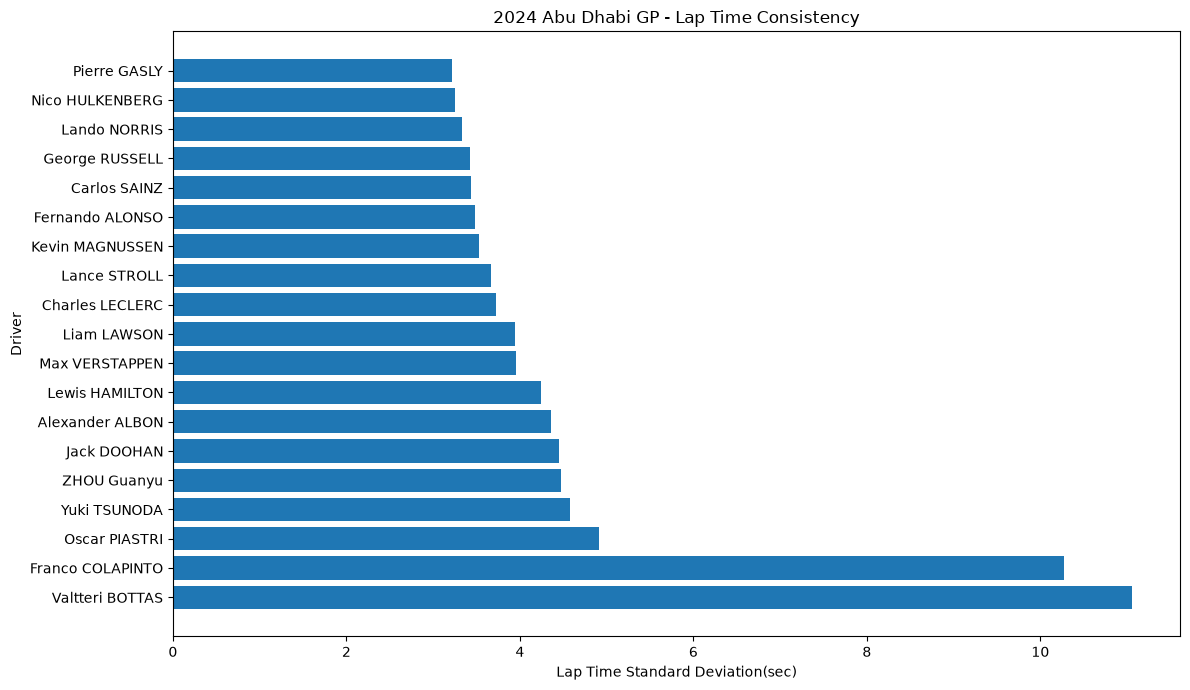

In [28]:
import matplotlib.pyplot as plt

consistency = driver_performance.sort_values(
    by="std"
)

plt.figure(figsize=(12,7))

plt.barh(
    consistency['full_name'],
    consistency['std']
)

plt.title("2024 Abu Dhabi GP - Lap Time Consistency")
plt.xlabel("Lap Time Standard Deviation(sec)")
plt.ylabel("Driver")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [29]:
print(
    consistency[
        ['full_name', 'team_name', 'mean', 'std', 'count']
    ].head(10).round(3)
)

          full_name     team_name    mean    std  count
8      Pierre GASLY        Alpine  90.465  3.216     57
9   Nico HULKENBERG  Haas F1 Team  90.521  3.257     57
0      Lando NORRIS       McLaren  89.232  3.332     57
4    George RUSSELL      Mercedes  89.868  3.430     57
1      Carlos SAINZ       Ferrari  89.335  3.439     57
7   Fernando ALONSO  Aston Martin  90.261  3.485     56
12  Kevin MAGNUSSEN  Haas F1 Team  90.755  3.524     53
11     Lance STROLL  Aston Martin  90.644  3.671     55
2   Charles LECLERC       Ferrari  89.771  3.719     57
13      Liam LAWSON            RB  90.903  3.948     52


- **Lower Standard Deviation** = More Consistent Lap times
- **Higher Standard Deviation** = Less Consistent Lap Times

***Engineering Observation:***

- Fatest driver is not the most consistent driver

*Lando Norris:*
Average = 89.232 s
Std     = 3.332 s

*Gasly:*
Average = 90.465 s
Std     = 3.216 s

Norris is **faster** but Gasly is more **consistent**

Moreover, std is also affected by things such as:
- pit-related laps
- traffic
- safety-car periods
- tyre condition
- fuel load
- race circumstances
- laps missing from the datasetstd is affected by things such as:
- pit-related laps
- traffic
- safety-car periods
- tyre condition
- fuel load
- race circumstances
- laps missing from the dataset

###Pace vs Consistency

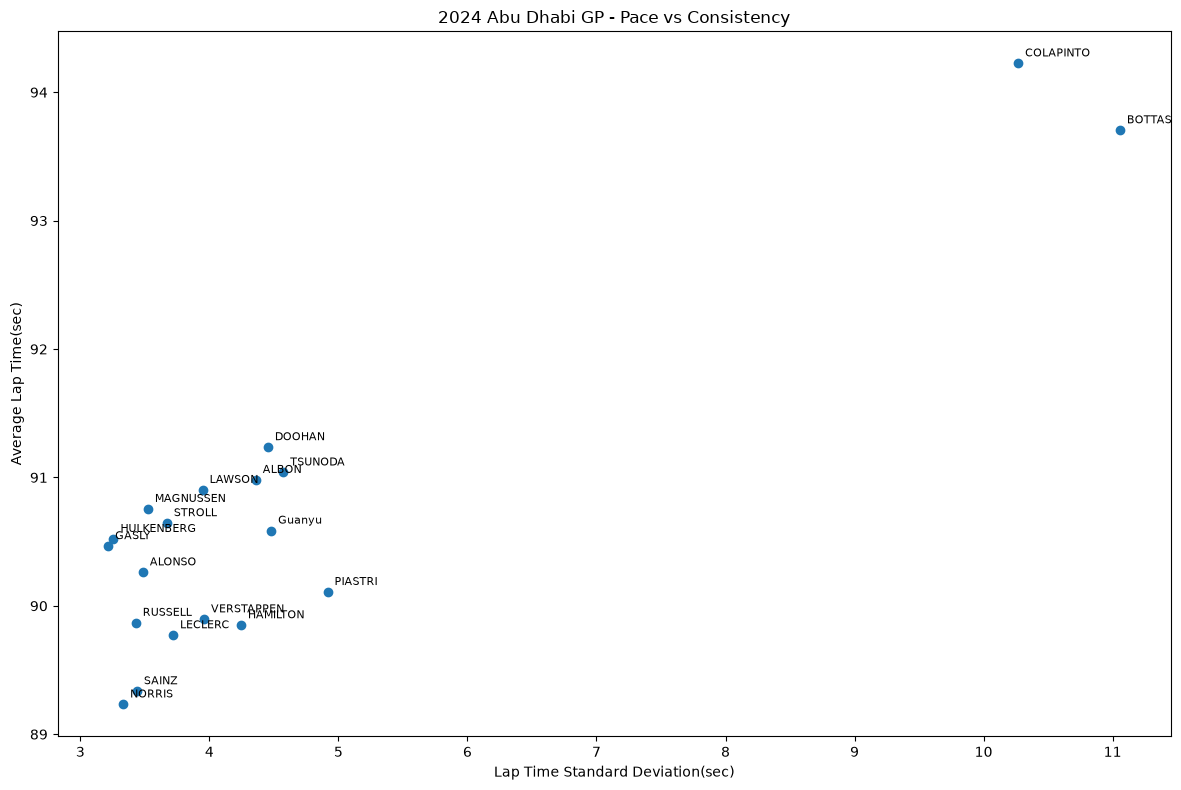

In [36]:
plt.figure(figsize=(12, 8))

plt.scatter(
    driver_performance['std'],
    driver_performance['mean']
)

# for adjusting labels use split function with row["full_name"]
for _, row in driver_performance.iterrows():
    plt.annotate(
        row['full_name'].split()[-1],
        (row['std'], row['mean']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8
    )

plt.title("2024 Abu Dhabi GP - Pace vs Consistency")
plt.xlabel("Lap Time Standard Deviation(sec)")
plt.ylabel("Average Lap Time(sec)")

plt.tight_layout()
plt.show()

- Actually, because lower is better for both axes, the ideal driver is toward the **bottom-left**.

In [31]:
%pip install adjustText

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


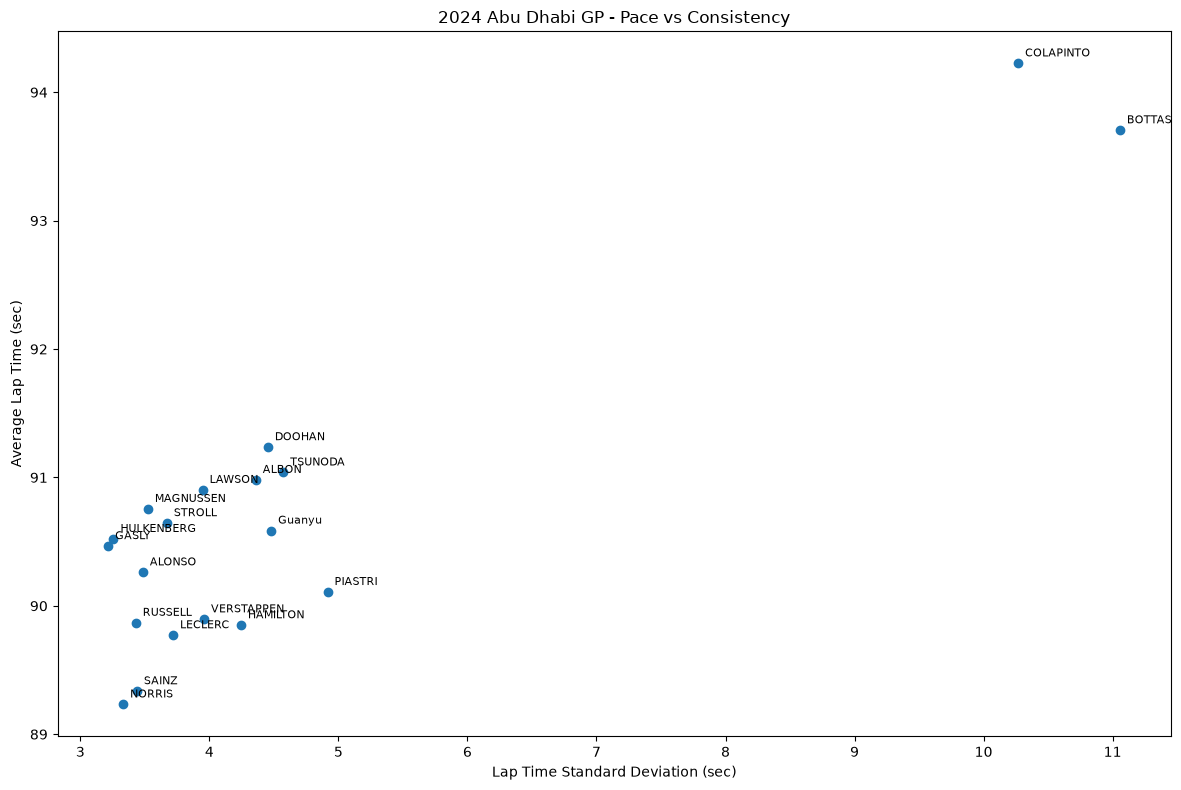

In [37]:
# For more adjusstment use adjust_text from adjustText 

from adjustText import adjust_text

plt.figure(figsize=(12, 8))

plt.scatter(
    driver_performance['std'],
    driver_performance['mean']
)

texts = []

for _, row in driver_performance.iterrows():
    plt.annotate(
        row['full_name'].split()[-1],
        (row['std'], row['mean']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8
    )

adjust_text(texts)

plt.xlabel('Lap Time Standard Deviation (sec)')
plt.ylabel('Average Lap Time (sec)')
plt.title('2024 Abu Dhabi GP - Pace vs Consistency')

plt.tight_layout()
plt.show()

- The axes are:
- **X-axis = standard deviation** → lower means more consistent
- **Y-axis = average lap time** → lower means faster
So the best region is bottom-left: fast and consistent.

- Lando Norris → ***89.232 s average***, 3.332 s std → **very fast** and reasonably consistent
- Carlos Sainz → 89.335 s, 3.439 s → very fast, slightly less consistent
- George Russell → 89.868 s, 3.430 s → fast and consistent
- Pierre Gasly → 90.465 s, **3.216 s** → ***most consistent***, but slower
- Nico Hülkenberg → 90.521 s, 3.257 s → also highly consistent
- #77 and #43 are far to the right and high up → much greater lap-time variation and slower average pace.


From the graph:
- Lando Norris has the strongest combination of low average lap time and relatively low variation.
- Carlos Sainz is also very fast with reasonably controlled variation.
- George Russell sits in a similar fast/consistent region.
- Pierre Gasly has the lowest standard deviation, but his average lap time is slower.
- Therefore, consistency alone doesn't determine race pace.

### V1 First Finding

**Race performance should be evaluated using multiple dimensions rather than a single metric.**

